# Volcano plots: differential gene and transcript isoform expression

One objective: show which genes and which transcript isoforms differ between the two groups, from the edgeR tables the pipeline wrote in S4.

In [1]:
source("src/volcano.R")
options(repr.plot.width = 7, repr.plot.height = 5)
results_dir <- "../LRP2_test_results"   # change to the results folder of the run
comparison  <- "HepG2_vs_K562"          # prefix of the S4 files

**Explanation.** The first line loads our plotting function. The next two lines are the only things to change for another run: the folder with the results, and the comparison name that starts every S4 file name.

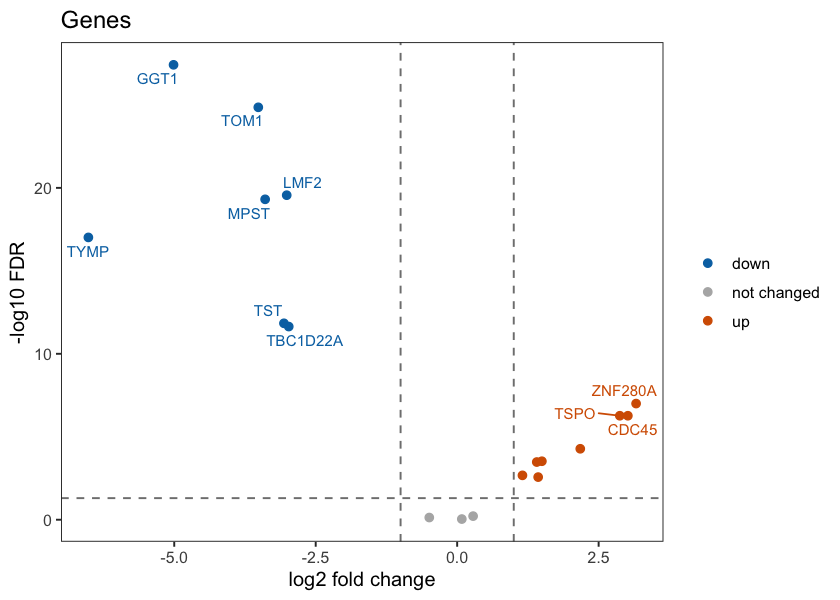

In [2]:
dge <- read_edger_results(file.path(results_dir, paste0(comparison, "_DGE_edgeR_results.txt")))
volcano_plot(dge, label_col = "gene_name", title = "Genes")

**Explanation.** Each point is a gene. Left to right is how much more or less it is expressed in one group (log2 fold change); height is how sure we are (-log10 of the false discovery rate, FDR). Dashed lines mark FDR 0.05 and a two-fold change; coloured points pass both. The most significant ones are named. Which group is 'up' is the group edgeR used as its second group, so check the M2 log before putting words on the figure.

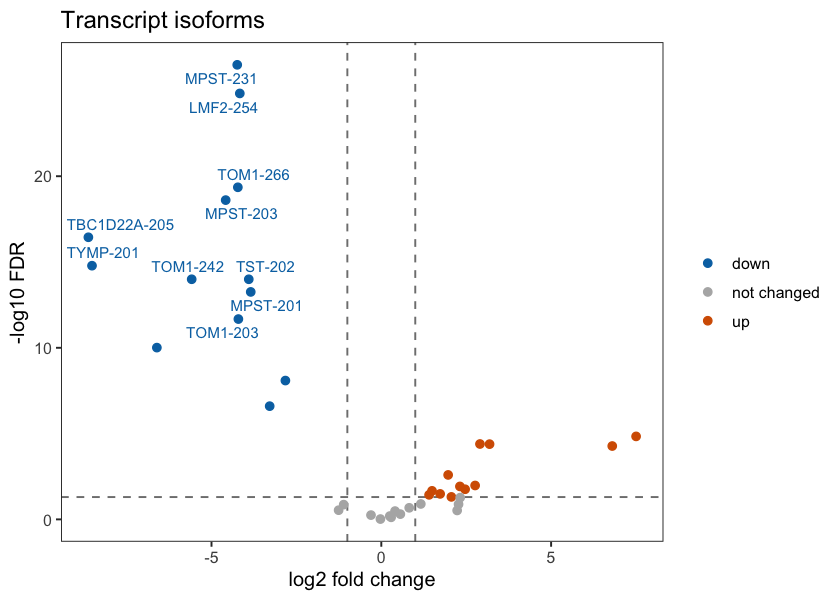

In [3]:
dte <- read_edger_results(file.path(results_dir, paste0(comparison, "_DTE_edgeR_results.txt")))
volcano_plot(dte, label_col = "transcript_name", title = "Transcript isoforms")

**Explanation.** The same plot for transcript isoforms. A gene can have one isoform that goes up and another that does not change, which the gene plot cannot show.

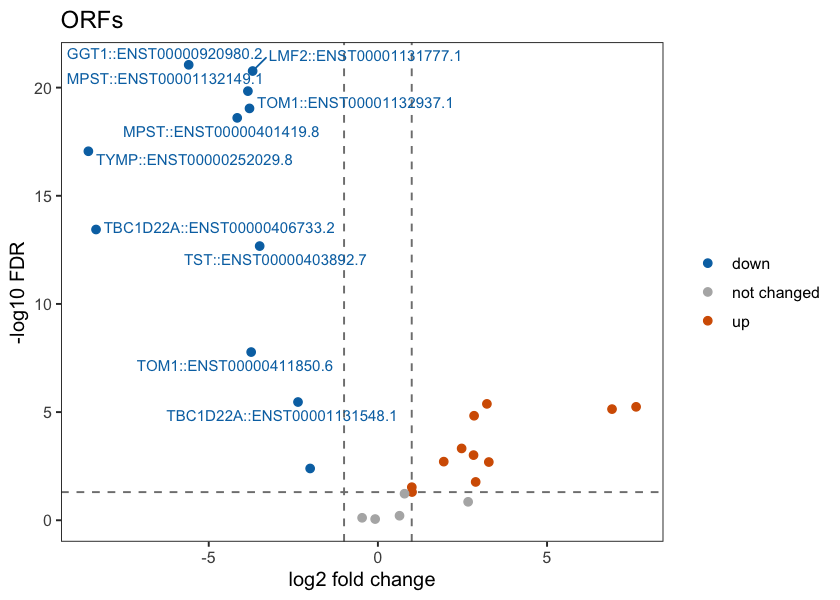

In [4]:
orf_file <- file.path(results_dir, paste0(comparison, "_DE_ORF_edgeR_results.txt"))
if (file.exists(orf_file)) {
  orf <- read_edger_results(orf_file)
  volcano_plot(orf, label_col = "orf_base_id", title = "ORFs")
} else {
  message("Not found: ", orf_file, " (download it from S4_MULTISAMPLE_ANALYSIS/M2_DIFFERENTIAL_EXPRESSION)")
}

**Explanation.** The same plot for open reading frames (ORFs), the predicted protein-coding stretches; each point is one ORF, named by its first transcript. If the results file is not in the results folder, the cell says so instead of failing.